# Assignment: K Nearest Neighbors on Wine Classification

## Objective

In this assignment, you will use K Nearest Neighbors (KNN) to classify wine samples into different wine classes.

You will practice:

- Loading and inspecting a classification dataset
- Training KNN without scaling
- Training KNN with scaling
- Choosing the value of \(K\)
- Comparing distance metrics
- Using distance-weighted KNN
- Using KNN imputation for missing values

This is a lightweight assignment. Focus on correct implementation and clear interpretation.

## Dataset

We will use the built-in Wine dataset from scikit-learn.

The dataset contains chemical measurements of wine samples. The target is the wine class.

This is a **multiclass classification problem**.

## 1. Setup

Run the install cell only if any package is missing.

In [ ]:
# Run this only if required.
# %pip install numpy pandas matplotlib seaborn scikit-learn

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the Dataset

Load the Wine dataset using `load_wine(as_frame=True)`.

In [ ]:
# TODO: Load the wine dataset.
# Hint: use load_wine(as_frame=True)

wine = load_wine(as_frame=True)

In [ ]:
# TODO: Create X and y.
# Hint:
# - X should contain the feature DataFrame.
# - y should contain the target values.

X = wine.data
y = wine.target

In [ ]:
# TODO: Display the first 5 rows of X and check the shape of X.

print("First 5 rows of X:")
print(X.head())
print("\nShape of X:", X.shape)

First 5 rows of X:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  


## 3. Check Class Distribution

Before training a classification model, check how many samples belong to each class.

In [ ]:
# TODO: Show count and percentage distribution of y.
# Hint: use value_counts() and value_counts(normalize=True)

print("Class distribution:")
print(y.value_counts())
print("\nPercentage distribution:")
print(y.value_counts(normalize=True) * 100)

Class distribution:
target
1    71
0    59
2    48
Name: count, dtype: int64

Percentage distribution:
target
1    39.887640
0    33.146067
2    26.966292
Name: proportion, dtype: float64


### Question 1

Is the Wine dataset heavily imbalanced? Why or why not?

Write your answer here:

No, the Wine dataset is not heavily imbalanced. As per the above percentage distribution, the three classes are fairly evenly spread:
- Class 0: 33%
- Class 1: 40%
- Class 2: 27%

A dataset is considered heavily imbalanced when one class has, for example, 85-90% of samples and another has only 15-10%. That is not the case here.

## 4. Train-Test Split

Use a stratified split so each wine class keeps a similar proportion in train and test data.

In [ ]:
# TODO: Split X and y into training and test sets.
# Use test_size=0.2, random_state=RANDOM_STATE, and stratify=y.

RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)

Shape of X_train: (142, 13)
Shape of X_test: (36, 13)


In [ ]:
# TODO: Check class distribution in y_train and y_test.

print("y_train distribution:")
print(y_train.value_counts().sort_index())

print("\ny_test distribution:")
print(y_test.value_counts().sort_index())

y_train distribution:
target
0    47
1    57
2    38
Name: count, dtype: int64

y_test distribution:
target
0    12
1    14
2    10
Name: count, dtype: int64


## 5. Baseline KNN Without Scaling

Train a KNN classifier without scaling.

Use:

```python
KNeighborsClassifier(n_neighbors=5)
```

This model is intentionally incomplete from a best-practice point of view. We will compare it with scaled KNN next.

In [ ]:
# TODO: Create and train a KNN model without scaling.
# TODO: Predict on X_test.
# Store predictions in y_pred_no_scaling.

knn_no_scaling = KNeighborsClassifier(n_neighbors=5)
knn_no_scaling.fit(X_train, y_train)
y_pred_no_scaling = knn_no_scaling.predict(X_test)

print("Predictions:", y_pred_no_scaling)

Predictions: [0 2 0 1 2 0 0 1 1 2 1 1 0 2 0 1 1 0 2 0 1 1 0 0 2 1 0 1 2 2 0 2 1 1 2 2]


Accuracy (No Scaling): 0.8055555555555556
Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.77      0.71      0.74        14
     class_2       0.64      0.70      0.67        10

    accuracy                           0.81        36
   macro avg       0.80      0.80      0.80        36
weighted avg       0.81      0.81      0.81        36



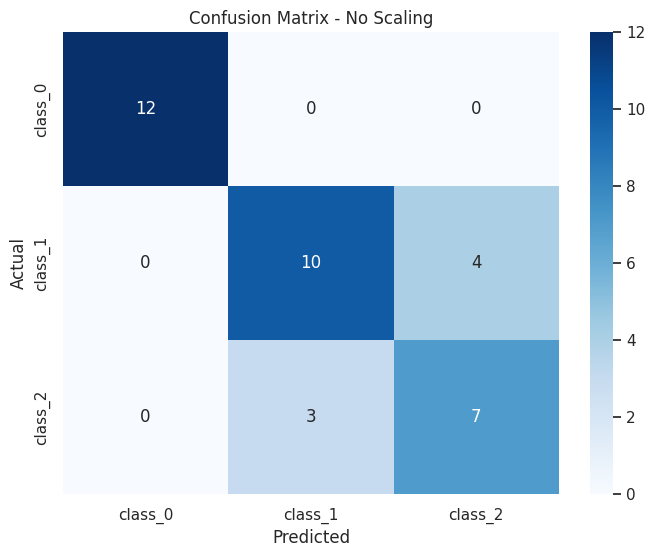

In [ ]:
# TODO: Print accuracy and classification report for the no-scaling model.
# TODO: Plot a confusion matrix.

# Accuracy
print("Accuracy (No Scaling):", accuracy_score(y_test, y_pred_no_scaling))

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred_no_scaling, target_names=wine.target_names))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_no_scaling)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=wine.target_names, yticklabels=wine.target_names)
plt.title("Confusion Matrix - No Scaling")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 6. KNN With Scaling

KNN is distance-based, so feature scaling is very important.

For standard scaling:

\[
x_j^{scaled}=\frac{x_j-\mu_j}{\sigma_j}
\]

Use a pipeline:

```text
StandardScaler -> KNeighborsClassifier
```

In [ ]:
# TODO: Create a pipeline with StandardScaler and KNeighborsClassifier(n_neighbors=5).
# TODO: Train the pipeline on X_train and y_train.
# TODO: Predict on X_test.
# Store predictions in y_pred_scaled.

# Create pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# Train
pipeline.fit(X_train, y_train)

# Predict
y_pred_scaled = pipeline.predict(X_test)

print("Predictions:", y_pred_scaled)

Predictions: [0 2 0 1 1 0 0 1 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 1 1 0 2 2 2 0 2 1 2 2 2]


Accuracy (With Scaling): 0.9722222222222222
Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      0.93      0.96        14
     class_2       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



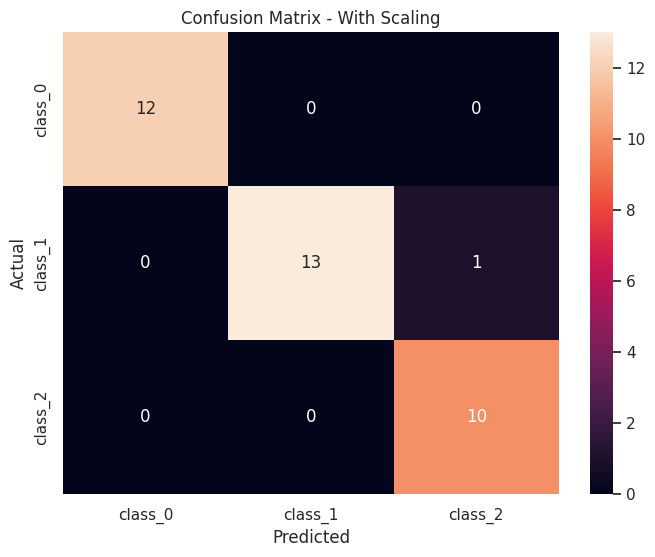

In [ ]:
# TODO: Print accuracy and classification report for the scaled model.
# TODO: Plot a confusion matrix.

# Accuracy
print("Accuracy (With Scaling):", accuracy_score(y_test, y_pred_scaled))

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred_scaled, target_names=wine.target_names))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_scaled)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=wine.target_names, yticklabels=wine.target_names)
plt.title("Confusion Matrix - With Scaling")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Question 2

Did scaling improve the model performance? Explain why scaling matters for KNN.

Write your answer here:

Yes, scaling improved the model performance. Accuracy went up from around 80% to 97%.

KNN works by measuring the distance between data points. Scaling makes all features use the same range. For example, if one measures distance using both kilometers and millimeters without converting, the kilometers will always win. Scaling converts everything to the same unit.

## 7. Choose the Value of \(K\)

Try multiple values of \(K\):

```python
[1, 3, 5, 7, 9, 11, 15]
```

Use cross-validation on the training data.

In [ ]:
k_values = [1, 3, 5, 7, 9, 11, 15]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# TODO: For each K, create a scaled KNN pipeline.
# TODO: Use cross_val_score on training data.
# TODO: Store mean CV accuracy for each K in a DataFrame.

mean_scores = []

for k in k_values:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    mean_scores.append(scores.mean())

k_results = pd.DataFrame({'K': k_values, 'Mean CV Accuracy': mean_scores})
print(k_results)

    K  Mean CV Accuracy
0   1          0.922660
1   3          0.936946
2   5          0.950739
3   7          0.957882
4   9          0.950739
5  11          0.957882
6  15          0.957882


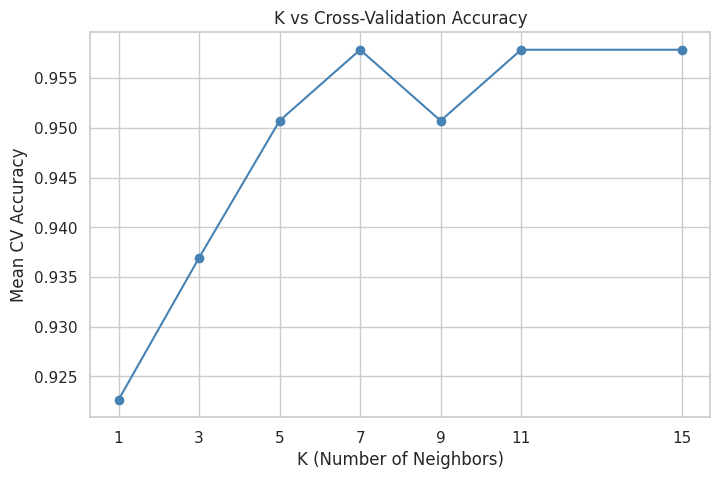

Best K: 7


In [ ]:
# TODO: Plot K vs cross-validation accuracy.
# TODO: Choose the best K based on CV accuracy.
# Store your selected value in best_k.

plt.figure(figsize=(8, 5))
plt.plot(k_results['K'], k_results['Mean CV Accuracy'], marker='o', color='steelblue')
plt.title('K vs Cross-Validation Accuracy')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Mean CV Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.show()

best_k = k_results.loc[k_results['Mean CV Accuracy'].idxmax(), 'K']
print("Best K:", best_k)

best_k = 7

### Question 3

What can happen when \(K=1\)? What can happen when \(K\) is very large?

Write your answer here:

- When K=1 the model looks at only the one nearest neighbor to make a decision. It memorizes the training data too closely (overfitting) and performs poorly on new data.

- When K is very large the model looks at too many neighbors, including ones that are far away and not really similar. It loses the ability to detect real patterns (underfitting).

- Therefore, a moderate K works best.

## 8. Compare Distance Metrics

Compare KNN with:

- Euclidean distance
- Manhattan distance

Use your selected `best_k` and scaling.

In [ ]:
# TODO: Compare metric="euclidean" and metric="manhattan" using cross-validation.
# TODO: Store results in a DataFrame.

metrics = ['euclidean', 'manhattan']
metric_scores = []

for metric in metrics:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=best_k, metric=metric))
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    metric_scores.append(scores.mean())

metric_results = pd.DataFrame({'Metric': metrics, 'Mean CV Accuracy': metric_scores})
print(metric_results)

best_metric = 'manhattan'

      Metric  Mean CV Accuracy
0  euclidean          0.957882
1  manhattan          0.978818


### Question 4

Which distance metric performed better? Was the difference large or small?

Write your answer here:

- Manhattan distance performed better (0.979).

- The difference is small, about 2%. Manhattan distance works slightly better here because the wine dataset has features on very different scales and distributions - Manhattan is less sensitive to large jumps in individual features.

## 9. Distance-Weighted KNN

In normal KNN, all neighbors vote equally.

In distance-weighted KNN, closer neighbors get more importance.

Compare:

```python
weights="uniform"
weights="distance"
```

In [ ]:
# TODO: Compare weights="uniform" and weights="distance" using cross-validation.
# Use best_k, scaling, and your preferred distance metric.
# Store results in a DataFrame.

weights_options = ['uniform', 'distance']
weight_scores = []

for w in weights_options:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=best_k, metric=best_metric, weights=w))
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    weight_scores.append(scores.mean())

weight_results = pd.DataFrame({'Weights': weights_options, 'Mean CV Accuracy': weight_scores})
print(weight_results)

    Weights  Mean CV Accuracy
0   uniform          0.978818
1  distance          0.978818


### Question 5

When might distance-weighted KNN be better than uniform voting?

Write your answer here:

Distance-weighted KNN is better when:
- The nearest neighbors are much closer than the farther ones - the close ones are more trustworthy.
- The decision boundary is complex and close neighbors matter more.

In our dataset, both methods gave the same result, meaning the neighbors were already well-separated after scaling.


## 10. Final KNN Model

Train your final model using:

- Scaling
- Selected \(K\)
- Selected distance metric
- Selected weighting method

Evaluate on the test data only once after making your choices.

Chosen configuration:
- K = 7
- Metric = manhattan
- Weights = uniform
- Scaling = yes

Final Model Accuracy: 1.0
Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



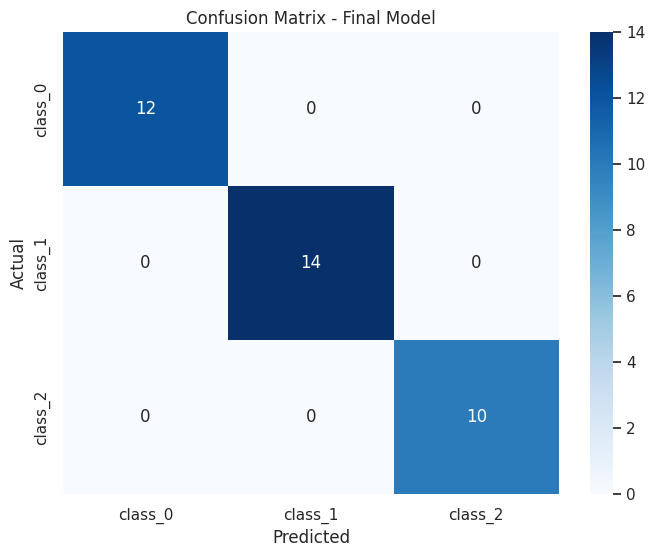

In [ ]:
# TODO: Create your final KNN pipeline.
# TODO: Train it on X_train and y_train.
# TODO: Predict on X_test.
# TODO: Report accuracy, classification report, and confusion matrix.

final_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=7, metric='manhattan', weights='uniform'))
])

final_pipe.fit(X_train, y_train)

y_pred_final = final_pipe.predict(X_test)

# Evaluate
print("Final Model Accuracy:", accuracy_score(y_test, y_pred_final))
print("Classification Report:")
print(classification_report(y_test, y_pred_final, target_names=wine.target_names))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=wine.target_names, yticklabels=wine.target_names)
plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 11. Mini Task: KNN Imputation

KNN can also be used to fill missing values using similar rows.

In this section, you will create a small amount of missing data and use `KNNImputer`.

In [ ]:
X_missing = X.copy()

# This randomly makes around 5% of values missing.
rng = np.random.default_rng(RANDOM_STATE)
missing_mask = rng.random(X_missing.shape) < 0.05
X_missing = X_missing.mask(missing_mask)

# Check missing values per column.
X_missing.isna().sum().sort_values(ascending=False).head(10)

,0
magnesium,12
proanthocyanins,12
nonflavanoid_phenols,11
color_intensity,10
alcalinity_of_ash,9
od280/od315_of_diluted_wines,9
total_phenols,8
alcohol,7
ash,7
malic_acid,7


In [ ]:
# TODO: Use KNNImputer to fill missing values.
# Hint:
# - Create KNNImputer with a small number of neighbors, for example 3 or 5.
# - Fit and transform X_missing.
# - Convert the result back into a DataFrame with the same column names.

imputer = KNNImputer(n_neighbors=5)
X_imputed = imputer.fit_transform(X_missing)
X_imputed = pd.DataFrame(X_imputed, columns=X_missing.columns)

print(X_imputed.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23       1.710  2.43               15.6      127.0           2.80   
1    13.20       1.780  2.14               11.2      100.0           2.65   
2    13.16       1.902  2.67               18.6      101.0           2.80   
3    14.37       1.950  2.50               16.8      113.0           3.85   
4    13.24       2.590  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

In [ ]:
# TODO: Verify that there are no missing values left after imputation.

print("Missing values after imputation:")
print(X_imputed.isna().sum().sum())

Missing values after imputation:
0


### Question 6

Why can scaling matter before KNN imputation?

Write your answer here:

KNN Imputer needs to find similar rows FIRST, then fill the gap (missing value).

Scaling must happen before this sequence, because the "find similar rows" step uses distance. Once wrong neighbors are chosen, no amount of scaling afterward can fix it.

## 12. Final Reflection Questions

Answer briefly.

### Question 7

What does a trained KNN model store?

Answer:

- A trained KNN model stores the entire training dataset. It does not learn any rules or equations during training. It simply memorises all training points and uses them at prediction time.

### Question 8

Why can KNN become slow when the dataset becomes very large?

Answer:

- Every time KNN needs to classify a new point, it must calculate the distance to every single training row, then sort them to find the K nearest.

- More data = more distances to calculate = much slower predictions.

### Question 9

Which final KNN configuration did you choose, and why?

Mention:

- \(K\)
- Distance metric
- Uniform or distance-weighted voting
- Final test accuracy

Answer:

I chose K=7, Manhattan distance, and uniform weights.
- K=7 was selected because it gave the highest CV accuracy among all tested values.
- Manhattan distance outperformed Euclidean in cross-validation.
- Both weighting methods gave the same result, so uniform was kept as it is simpler.
- Scaling was applied using StandardScaler. The final test accuracy was 1.0 (100%).

## Submission Checklist

Submit your completed notebook with:

- All code cells executed
- K comparison table or plot
- Distance metric comparison
- Uniform vs distance-weighted comparison
- Final model evaluation
- KNN imputation result
- Answers to all questions